# Garbage Classification — Khám phá dữ liệu ảnh (EDA)

**Mục tiêu:** khảo sát dữ liệu cho Simple CNN, Complex CNN và transfer learning: phân bố lớp, đặc điểm ảnh, ảnh lỗi, trùng và ứng viên gần trùng.

**Phạm vi:** chỉ EDA; không sửa/xóa ảnh, không chia tập, augmentation hoặc huấn luyện.

Nguồn: [Mostafa Mohamed — Garbage Classification (12 classes)](https://www.kaggle.com/datasets/mostafaabla/garbage-classification).
Metadata lúc tải ghi nhận **15.515 ảnh / 12 lớp**. Notebook kiểm kê lại dữ liệu hiện tại và đối chiếu `data/raw/dataset_info.json`; đây là số đếm khi tải, không phải số ảnh công bố trên Kaggle.

**Cách chạy:** chọn Python kernel và Run All. Thư viện: `numpy`, `pandas`, `matplotlib`, `Pillow`, `scipy`, `IPython`.
Chỉnh `DATA_DIR` nếu cần. Kết quả lưu tại `preprocess/eda_outputs/garbage_classification/`.
CSV chứa toàn bộ kết quả; hình xem lại được phân trang bằng `REVIEW_START`, `REVIEW_LIMIT` (đặt `None` để xem tất cả).


In [1]:
from pathlib import Path
from io import BytesIO
from concurrent.futures import ThreadPoolExecutor
from collections import defaultdict
import hashlib
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image, ImageOps
import scipy
from scipy.fft import dctn
from IPython.display import display, Markdown

SEED = 42
PHASH_THRESHOLD = 4
REVIEW_START = 0
REVIEW_LIMIT = 12  # None: hiển thị tất cả nhóm; CSV luôn chứa toàn bộ kết quả
CLASSES = ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes',
           'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
DATA_DIR = None  # Ví dụ: Path(r'C:/datasets/garbage_classification')
if DATA_DIR is None:
    candidates = [base / relative
                  for base in (Path.cwd(), *Path.cwd().parents)
                  for relative in ['data/raw/garbage_classification',
                                   'deep_learning-waste_classification/data/raw/garbage_classification']]
    DATA_DIR = next((p for p in candidates if p.is_dir()), None)
if DATA_DIR is None or not Path(DATA_DIR).is_dir():
    raise FileNotFoundError('Hãy chỉnh DATA_DIR thành thư mục chứa 12 thư mục class.')
DATA_DIR = Path(DATA_DIR).resolve()
REPO_DIR = next((base for base in (Path.cwd(), *Path.cwd().parents)
                 if (base / 'preprocess').is_dir() and (base / 'data').is_dir()), None)
if REPO_DIR is None:
    REPO_DIR = next((base / 'deep_learning-waste_classification'
                     for base in (Path.cwd(), *Path.cwd().parents)
                     if (base / 'deep_learning-waste_classification/preprocess').is_dir()), None)
if REPO_DIR is None:
    raise FileNotFoundError('Chạy notebook từ workspace, repo hoặc preprocess.')
OUTPUT_DIR = REPO_DIR / 'preprocess/eda_outputs/garbage_classification'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
metadata_path = DATA_DIR.parent / 'dataset_info.json'
metadata = json.loads(metadata_path.read_text(encoding='utf-8')) if metadata_path.exists() else {}
EXPECTED = metadata.get('class_counts', {})
missing_classes = [c for c in CLASSES if not (DATA_DIR / c).is_dir()]
extra_classes = [p.name for p in DATA_DIR.iterdir() if p.is_dir() and p.name not in CLASSES]
print('Dataset:', DATA_DIR)
print('Thiếu lớp:', missing_classes, '| Thư mục ngoài 12 lớp:', extra_classes)
assert not missing_classes and not extra_classes, 'Kiểm tra cấu trúc nhãn trước khi chạy EDA.'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
COLORS = dict(zip(CLASSES, plt.get_cmap('tab20').colors[:12]))

def finish_figure(fig, filename=None):
    fig.tight_layout()
    if filename:
        fig.savefig(OUTPUT_DIR / filename, dpi=130, bbox_inches='tight')
    plt.show()
    plt.close(fig)


Matplotlib is building the font cache; this may take a moment.


Dataset: C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data\raw\garbage_classification
Thiếu lớp: [] | Thư mục ngoài 12 lớp: []


## 1. Kiểm kê và đọc ảnh

Mỗi dòng tương ứng một file ảnh, nhãn lấy từ tên thư mục. Kiểm tra khả năng giải mã, định dạng, số kênh, kích thước, dung lượng và thông tin EXIF. Các file lỗi được ghi nhận riêng, không tự động xóa.

Độ sáng và độ tương phản được đo trên ảnh xám với thang 0–255. Chỉ số chi tiết là phương sai Laplacian trên ảnh xám thu về 128 × 128 để so sánh cùng thang kích thước; đây là chỉ báo tương đối, **không phải kết luận ảnh bị mờ**.

In [2]:
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
all_paths = sorted(p for p in DATA_DIR.rglob('*') if p.is_file())
paths = [p for p in all_paths if p.suffix.lower() in EXTENSIONS]
other_files = [p.relative_to(DATA_DIR).as_posix() for p in all_paths
               if p.suffix.lower() not in EXTENSIONS]
assert paths, 'Không tìm thấy ảnh. Kiểm tra DATA_DIR.'
rows = []
def read_image_bytes(p):
    try:
        return p, p.read_bytes(), None
    except OSError as exc:
        return p, b'', str(exc)

# Song song hóa I/O; giải mã và thu warnings tuần tự để kết quả ổn định.
with ThreadPoolExecutor(max_workers=8) as pool:
    file_payloads = list(pool.map(read_image_bytes, paths))
for number, (p, payload, read_error) in enumerate(file_payloads, start=1):
    row = {'filepath': p.relative_to(DATA_DIR).as_posix(),
           'label': p.relative_to(DATA_DIR).parts[0], 'size_kb': len(payload) / 1024,
           'status': 'ok', 'error': '', 'warning': ''}
    try:
        if read_error:
            raise OSError(read_error)
        row['file_sha256'] = hashlib.sha256(payload).hexdigest()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            with Image.open(BytesIO(payload)) as im:
                im.verify()
            with Image.open(BytesIO(payload)) as im:
                im.load()
                row.update(format=im.format, mode=im.mode, channels=len(im.getbands()),
                           width=im.width, height=im.height,
                           exif_orientation=im.getexif().get(274, 1))
                rgb = ImageOps.exif_transpose(im).convert('RGB')
                row.update(display_width=rgb.width, display_height=rgb.height)
                row['pixel_sha256'] = hashlib.sha256(
                    str(rgb.size).encode() + rgb.tobytes()).hexdigest()
                gray = np.asarray(rgb.convert('L'), dtype=np.float32)
                small = np.asarray(rgb.convert('L').resize((128, 128)), dtype=np.float32)
                lap = (small[:-2, 1:-1] + small[2:, 1:-1] + small[1:-1, :-2]
                       + small[1:-1, 2:] - 4 * small[1:-1, 1:-1])
                row.update(brightness=float(gray.mean()), contrast=float(gray.std()),
                           detail_score=float(lap.var()),
                           dark_fraction=float((gray <= 10).mean()),
                           bright_fraction=float((gray >= 245).mean()))
                low = dctn(np.asarray(rgb.convert('L').resize((32, 32)), dtype=float),
                           type=2, norm='ortho')[:8, :8].ravel()[1:]
                row['phash'] = f"{sum(int(v) << i for i, v in enumerate(low > np.median(low))):016x}"
            row['warning'] = ' | '.join(str(w.message) for w in caught)
    except Exception as exc:
        row.update(status='error', error=f'{type(exc).__name__}: {exc}')
    rows.append(row)
    if number % 3000 == 0:
        print(f'Đã khảo sát {number:,}/{len(paths):,} ảnh', flush=True)
del file_payloads
inventory = pd.DataFrame(rows)
valid = inventory.loc[inventory.status.eq('ok')].copy()
assert len(valid), 'Không có ảnh đọc được.'
valid['aspect_ratio'] = valid.display_width / valid.display_height
print(f'Tổng file ảnh: {len(inventory):,}; đọc được: {len(valid):,}; lỗi: {(inventory.status != "ok").sum()}')
print(f'File ngoài định dạng khảo sát: {len(other_files)}')
display(inventory.head().drop(columns=['file_sha256', 'pixel_sha256', 'phash'], errors='ignore'))
issues = inventory.loc[inventory.status.ne('ok') | inventory.warning.ne(''),
                       ['filepath', 'status', 'error', 'warning']]
display(issues if len(issues) else pd.DataFrame({'Kết quả': ['Không phát hiện lỗi đọc/cảnh báo.']}))
inventory.to_csv(OUTPUT_DIR / 'image_inventory.csv', index=False)
issues.to_csv(OUTPUT_DIR / 'image_issues.csv', index=False)
pd.DataFrame({'filepath': other_files}).to_csv(OUTPUT_DIR / 'other_files.csv', index=False)


Đã khảo sát 3,000/15,515 ảnh


Đã khảo sát 6,000/15,515 ảnh


Đã khảo sát 9,000/15,515 ảnh


Đã khảo sát 12,000/15,515 ảnh


Đã khảo sát 15,000/15,515 ảnh


Tổng file ảnh: 15,515; đọc được: 15,515; lỗi: 0
File ngoài định dạng khảo sát: 0


,filepath,label,size_kb,status,error,warning,format,mode,channels,width,height,exif_orientation,display_width,display_height,brightness,contrast,detail_score,dark_fraction,bright_fraction
0,battery/battery1.jpg,battery,7.231445,ok,,,JPEG,RGB,3,280,180,1,280,180,143.018982,52.575737,2386.824951,0.004583,0.002837
1,battery/battery10.jpg,battery,4.785156,ok,,,JPEG,RGB,3,220,165,1,220,165,199.644745,83.455826,3768.403076,0.000992,0.634848
2,battery/battery100.jpg,battery,12.671875,ok,,,JPEG,RGB,3,275,183,1,275,183,89.309807,55.886223,4080.673096,0.042126,0.000079
3,battery/battery101.jpg,battery,9.594727,ok,,,JPEG,RGB,3,275,183,1,275,183,228.013535,55.591724,2436.091309,0.001788,0.770611
4,battery/battery102.jpg,battery,3.038086,ok,,,JPEG,RGB,3,224,224,1,224,224,228.800461,62.146416,680.380676,0.004305,0.817582


,Kết quả
0,Không phát hiện lỗi đọc/cảnh báo.


## 2. Phân bố lớp và mức độ mất cân bằng

Đối chiếu số file hiện tại với metadata lúc tải; tính riêng ảnh đọc được và tỷ trọng từng lớp.
Không coi metadata là xác nhận nhãn đúng. Nếu không có metadata thì cột đối chiếu để trống.


,download_count,local_files,readable_images,percent_readable,difference_from_download
battery,945,945,945,6.09,0
biological,985,985,985,6.35,0
brown-glass,607,607,607,3.91,0
cardboard,891,891,891,5.74,0
clothes,5325,5325,5325,34.32,0
green-glass,629,629,629,4.05,0
metal,769,769,769,4.96,0
paper,1050,1050,1050,6.77,0
plastic,865,865,865,5.58,0
shoes,1977,1977,1977,12.74,0


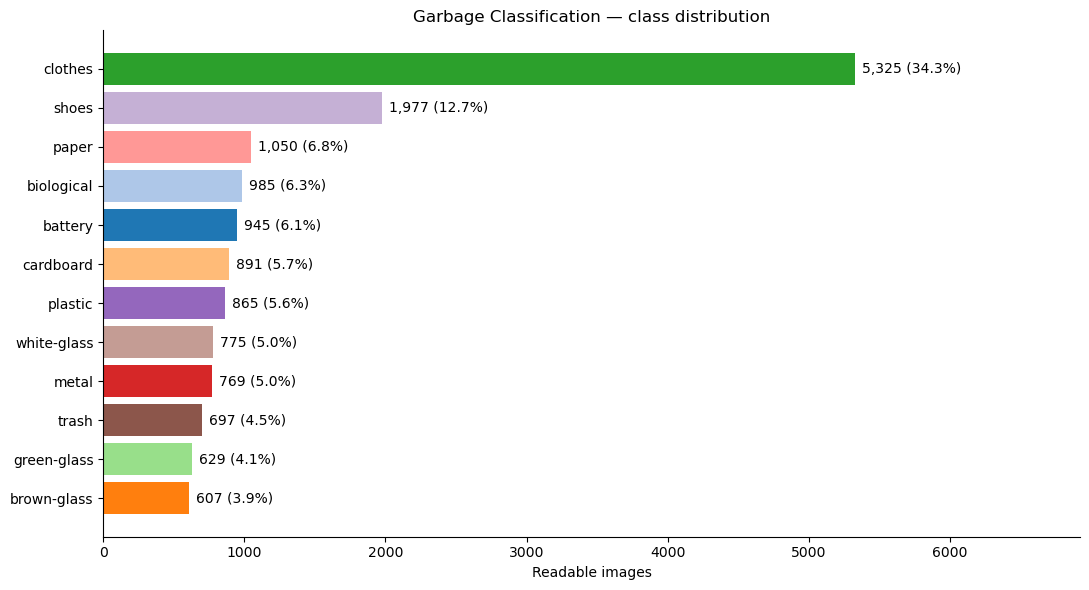

**Nhận xét:** nhiều nhất là **clothes** (5,325 ảnh), ít nhất là **brown-glass** (607 ảnh). Tỷ lệ lớn nhất/nhỏ nhất có ảnh: **8.77 lần**. Luôn đoán lớp đông nhất sẽ đạt **34.32%** trên tập dữ liệu hiện tại (không phải kết quả mô hình trên test). Nên báo cáo macro-F1 và recall từng lớp.

In [3]:
counts = valid.label.value_counts().reindex(CLASSES, fill_value=0)
distribution = pd.DataFrame({
    'download_count': pd.Series(EXPECTED, dtype='Int64').reindex(CLASSES),
    'local_files': inventory.label.value_counts().reindex(CLASSES, fill_value=0),
    'readable_images': counts})
distribution['percent_readable'] = (counts / counts.sum() * 100).round(2)
distribution['difference_from_download'] = distribution.local_files - distribution.download_count
display(distribution)
distribution.to_csv(OUTPUT_DIR / 'class_distribution.csv', index_label='label')
ordered = counts.sort_values()
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(ordered.index, ordered.values, color=[COLORS[c] for c in ordered.index])
ax.bar_label(bars, labels=[f'{n:,} ({n/counts.sum():.1%})' for n in ordered], padding=5)
ax.set(xlabel='Readable images', title='Garbage Classification — class distribution',
       xlim=(0, counts.max()*1.3))
finish_figure(fig, 'class_distribution.png')
imbalance = counts.max() / counts[counts > 0].min()
majority_baseline = counts.max() / counts.sum()
display(Markdown(f'**Nhận xét:** nhiều nhất là **{counts.idxmax()}** ({counts.max():,} ảnh), '
                 f'ít nhất là **{counts.idxmin()}** ({counts.min():,} ảnh). '
                 f'Tỷ lệ lớn nhất/nhỏ nhất có ảnh: **{imbalance:.2f} lần**. '
                 f'Luôn đoán lớp đông nhất sẽ đạt **{majority_baseline:.2%}** trên tập dữ liệu hiện tại '
                 '(không phải kết quả mô hình trên test). Nên báo cáo macro-F1 và recall từng lớp.'))


## 3. Quan sát ảnh mẫu theo class

Lấy mẫu có seed cố định để chạy lại cho cùng kết quả. Quan sát hình dạng, màu sắc, nền, độ che khuất và khả năng nhầm nhãn. Ảnh mẫu không đại diện đầy đủ cho mọi ảnh trong class.

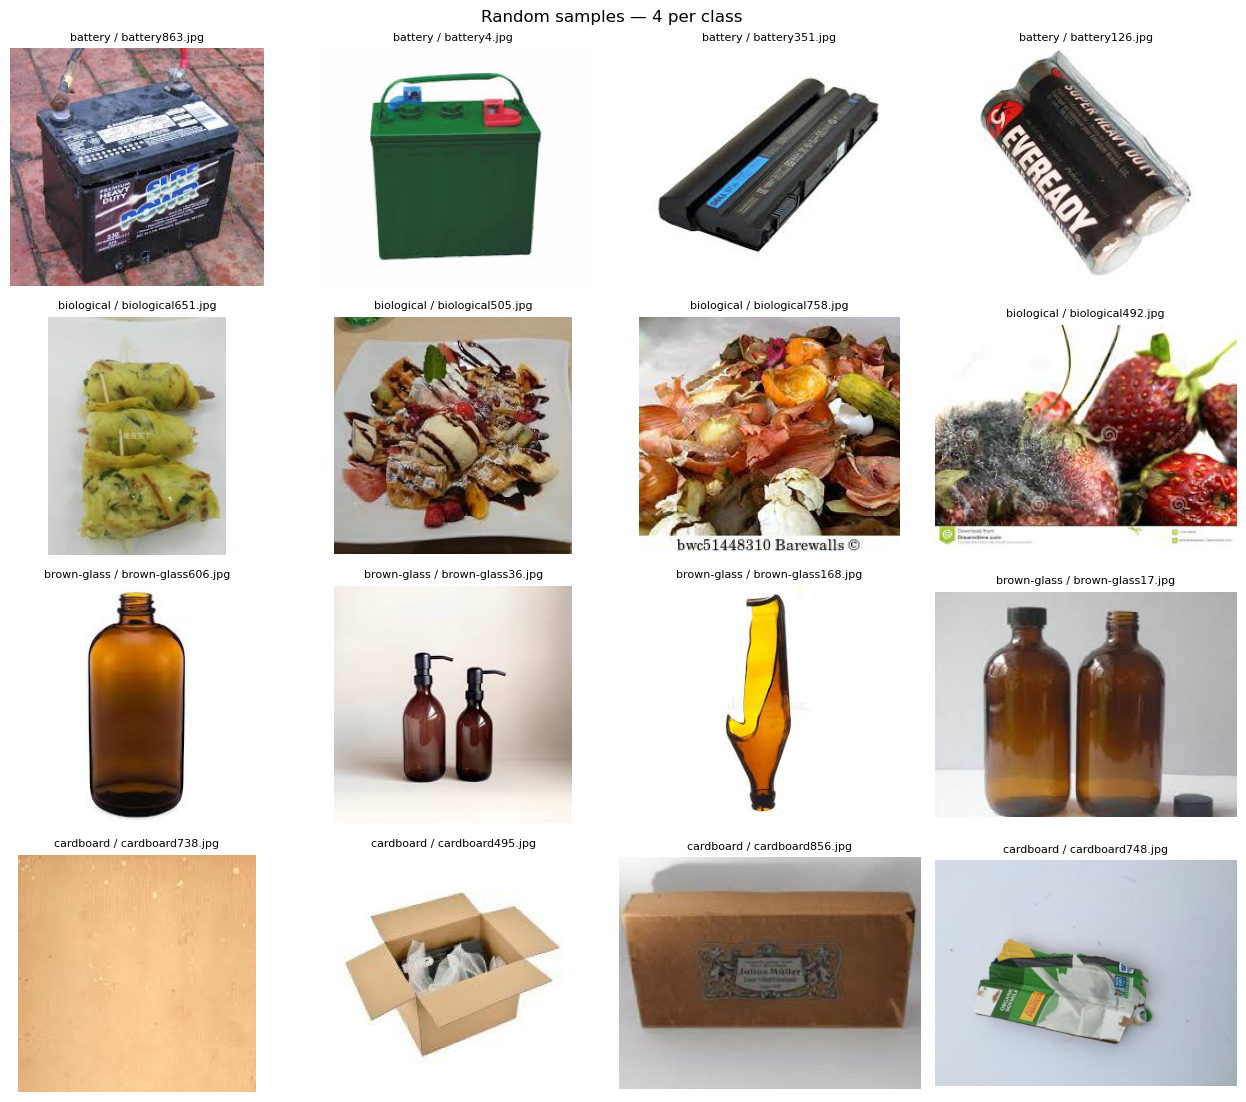

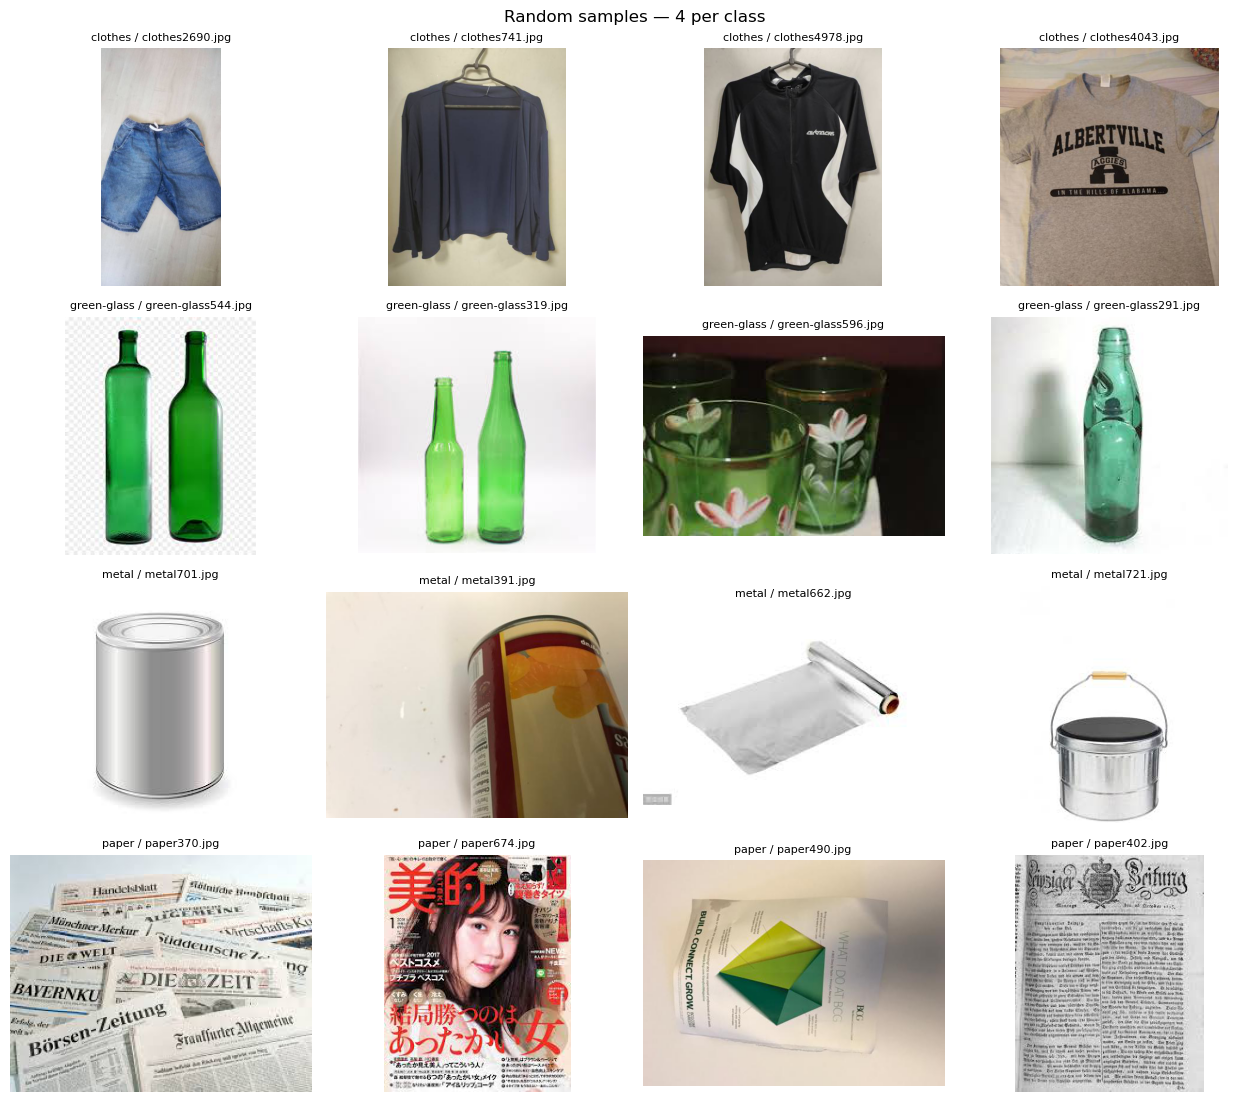

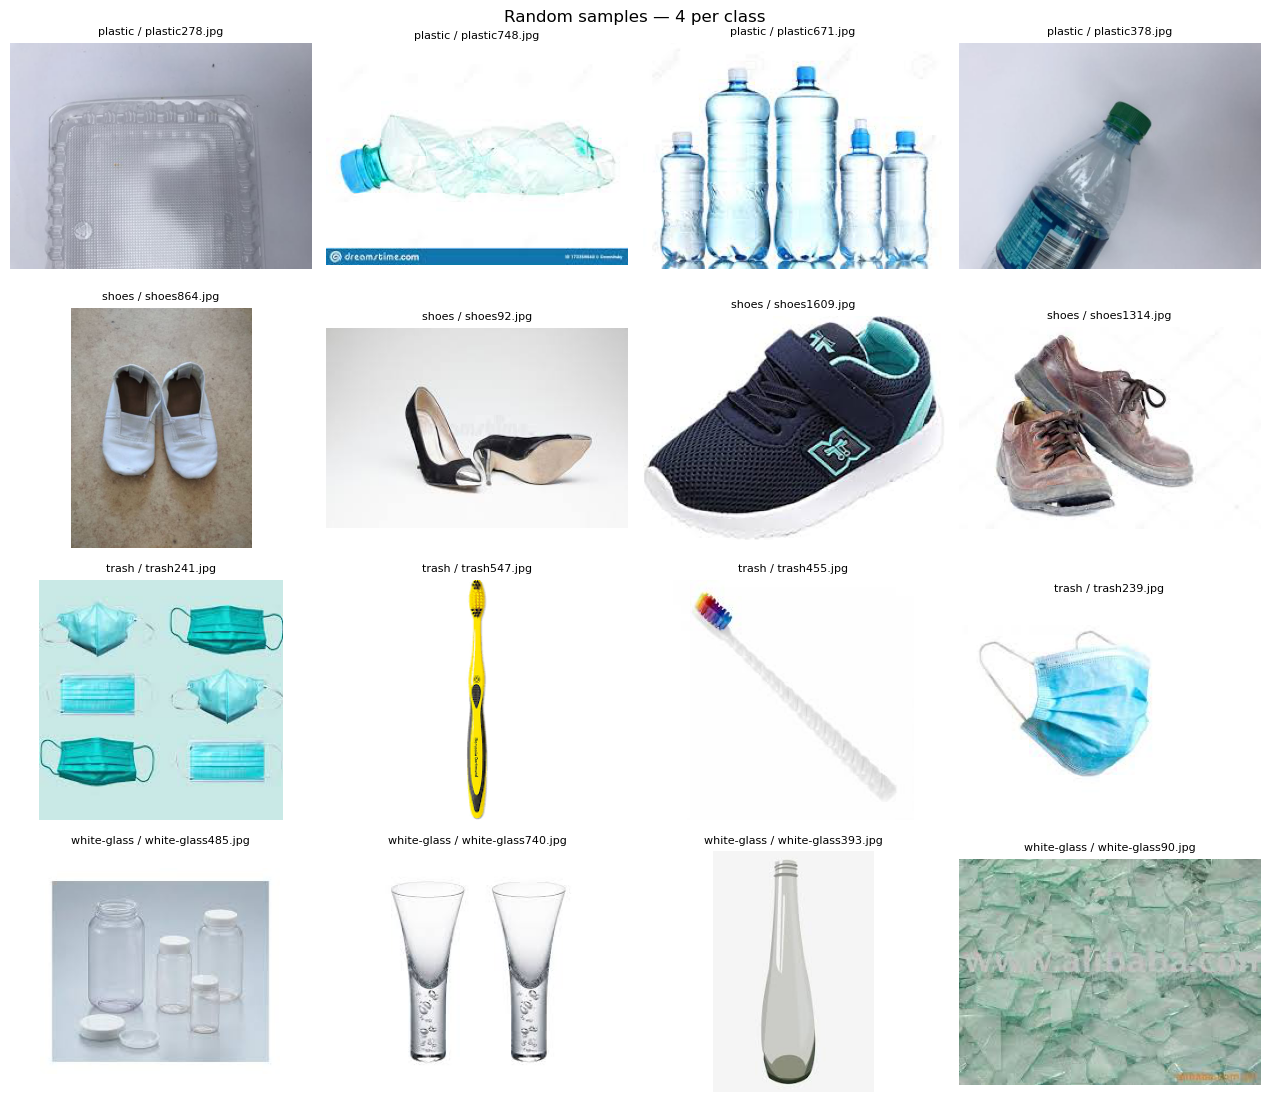

In [4]:
def show_gallery(frame, title, columns=4, filename=None):
    if frame.empty:
        print('Không có ảnh để hiển thị.')
        return
    rows_count = int(np.ceil(len(frame)/columns))
    fig, axes = plt.subplots(rows_count, columns,
                             figsize=(columns*3.2, rows_count*2.8), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, (_, row) in zip(axes.flat, frame.iterrows()):
        with Image.open(DATA_DIR / row.filepath) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
        ax.set_title(f'{row.label} / {Path(row.filepath).name}', fontsize=8)
    fig.suptitle(title)
    finish_figure(fig, filename)

samples = pd.concat([valid.loc[valid.label.eq(c)].sample(n=min(4, counts[c]), random_state=SEED)
                     for c in CLASSES])
for start in range(0, len(CLASSES), 4):
    selected = CLASSES[start:start+4]
    show_gallery(samples.loc[samples.label.isin(selected)],
                 'Random samples — 4 per class', filename=f'samples_{start//4+1}.png')


## 4. Kích thước và định dạng ảnh

Kiểm tra kích thước, format và mode để biết ảnh có nhất quán và có thể đưa vào cùng một quy trình tiền xử lý hay không.

,width,height
count,15515.000,15515.000
mean,349.822,351.706
std,117.549,149.418
min,51.000,100.000
25%,234.000,224.000
50%,400.000,384.000
75%,400.000,533.000
max,888.000,936.000


,format,mode,images
0,JPEG,RGB,15481
1,PNG,P,34


**Kết luận:** Có khác biệt về kích thước, format hoặc mode; cần kiểm tra trước khi tiền xử lý.

,width,height,images
609,400,533,2590
824,512,384,2358
245,225,225,2004
610,400,534,1077
359,275,183,691
330,259,194,550
831,533,400,388
717,400,711,300
143,194,259,230
832,534,400,163


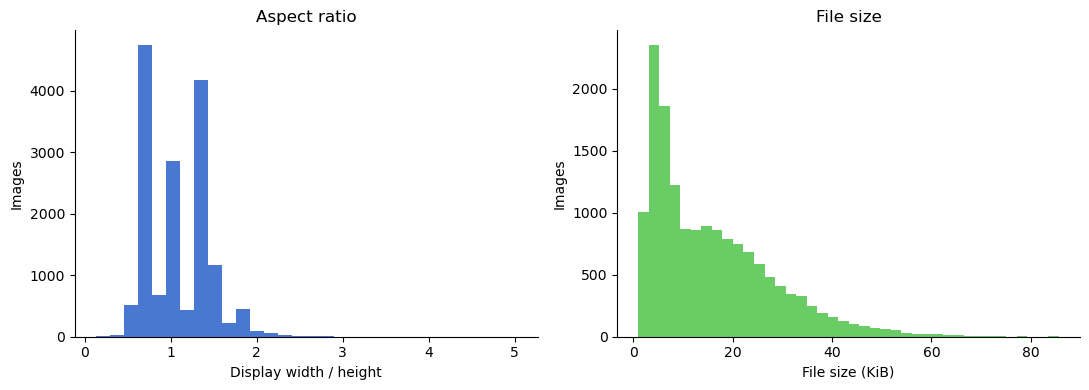

In [5]:
dimension_summary = valid[['width', 'height']].describe().round(3)
format_summary = (valid.groupby(['format', 'mode']).size()
                  .rename('images').reset_index()
                  .sort_values('images', ascending=False))

display(dimension_summary)
display(format_summary)

dimensions = valid[['width', 'height']].drop_duplicates()
formats = valid['format'].nunique()
modes = valid['mode'].nunique()

if len(dimensions) == 1 and formats == 1 and modes == 1:
    result = (f'Tất cả {len(valid):,} ảnh có cùng kích thước '
              f'{int(dimensions.iloc[0].width)} × {int(dimensions.iloc[0].height)}, '
              f'format {valid["format"].iloc[0]} và mode {valid["mode"].iloc[0]}.')
else:
    result = 'Có khác biệt về kích thước, format hoặc mode; cần kiểm tra trước khi tiền xử lý.'

display(Markdown(f'**Kết luận:** {result}'))
dimension_summary.to_csv(OUTPUT_DIR / 'dimension_summary.csv')
format_summary.to_csv(OUTPUT_DIR / 'format_summary.csv', index=False)
dimension_counts = valid.groupby(['width', 'height']).size().rename('images').reset_index()
display(dimension_counts.sort_values('images', ascending=False).head(15))
dimension_counts.to_csv(OUTPUT_DIR / 'dimension_counts.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(valid.aspect_ratio, bins=30, color='#4878D0')
axes[0].set(xlabel='Display width / height', ylabel='Images', title='Aspect ratio')
axes[1].hist(valid.size_kb, bins=40, color='#6ACC64')
axes[1].set(xlabel='File size (KiB)', ylabel='Images', title='File size')
finish_figure(fig, 'dimensions_and_sizes.png')


## 5. Độ sáng và độ tương phản

Kiểm tra điều kiện ánh sáng giữa các class. Kết quả chỉ dùng để quyết định có cần chuẩn hóa hoặc augmentation về brightness/contrast hay không; không tạo thêm feature cho mô hình.

brightness         contrast        detail_score         
                  mean  median     mean median         mean   median
label                                                               
battery         189.05  196.10    74.21  75.21      2319.07  1925.36
biological      144.99  138.12    56.32  55.99      1683.23  1313.18
brown-glass     175.49  176.03    68.67  68.65      1098.12   840.34
cardboard       170.57  165.18    46.11  46.46       754.10   524.72
clothes         126.71  127.86    54.03  53.83      1346.64   892.60
green-glass     179.03  180.40    59.16  58.89      1024.18   788.38
metal           176.69  175.64    53.64  53.74      1462.88  1038.14
paper           167.85  171.78    53.16  54.96      3160.88  2595.40
plastic         183.59  176.50    39.94  38.23       848.89   502.54
shoes           164.19  162.92    63.10  62.26      1480.23  1268.98
trash           222.72  235.26    30.33  27.87       525.50   356.61
white-glass     200.73  207.44    33.33  32.51       742.07   554.53

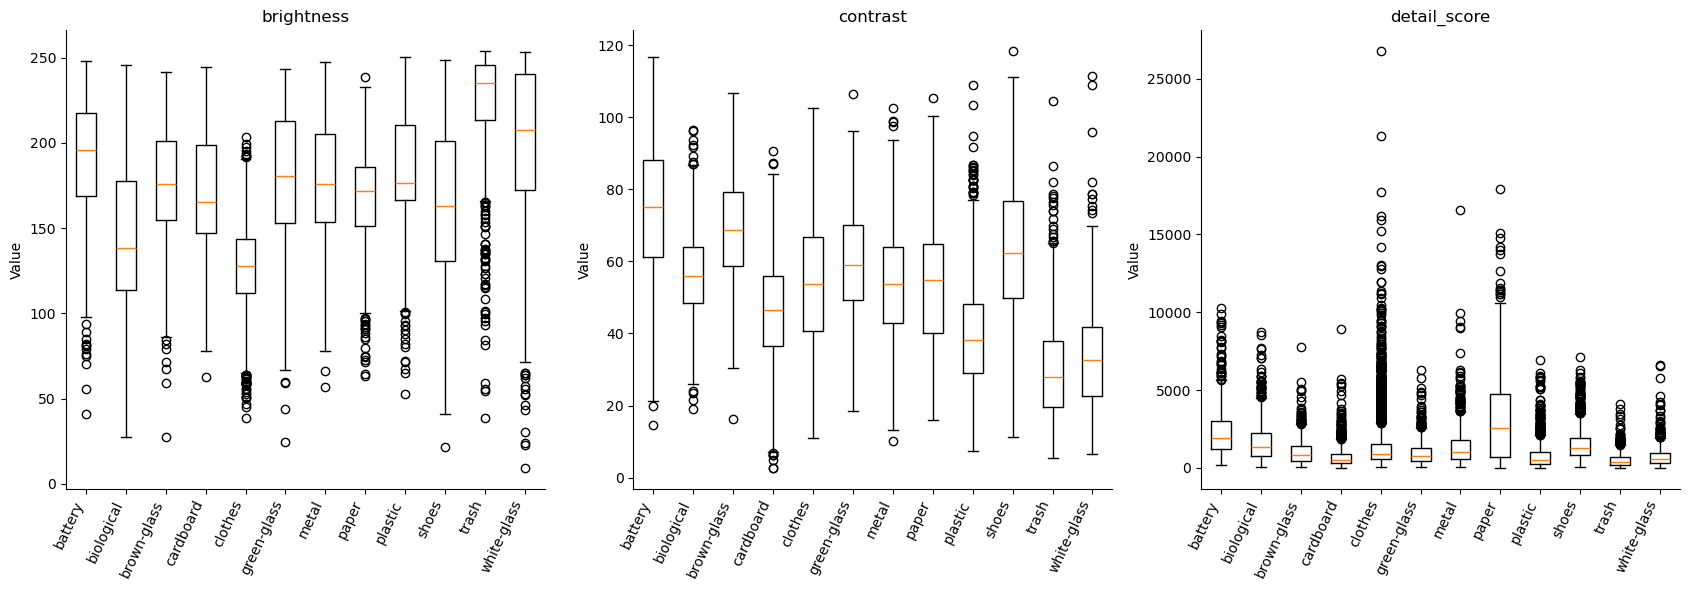

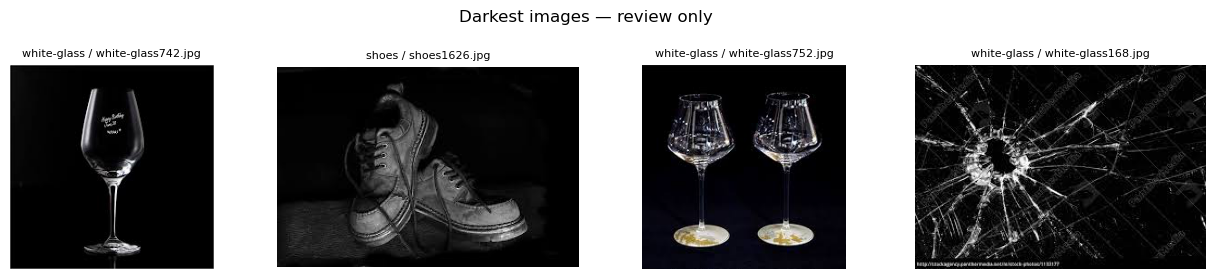

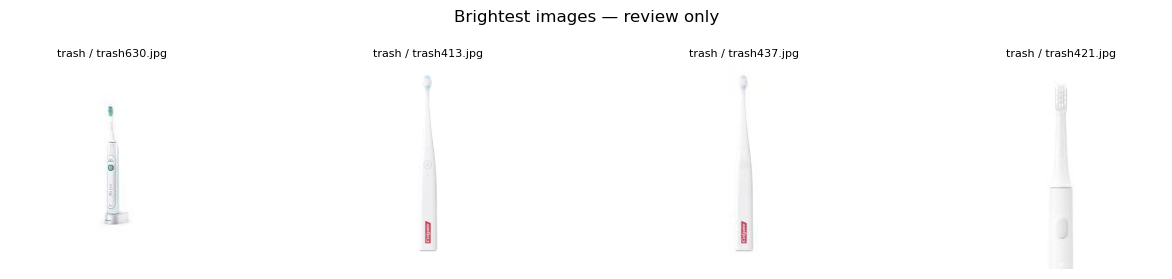

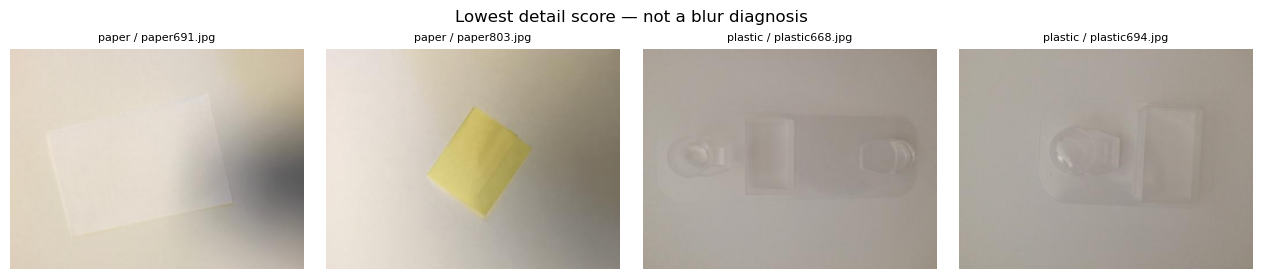

In [6]:
metrics = ['brightness', 'contrast', 'detail_score']
metric_summary = valid.groupby('label')[metrics].agg(['mean', 'median']).round(2)
display(metric_summary)
metric_summary.to_csv(OUTPUT_DIR / 'quality_by_class.csv')
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, metric in zip(axes, metrics):
    ax.boxplot([valid.loc[valid.label.eq(c), metric] for c in CLASSES])
    ax.set_xticks(range(1, len(CLASSES)+1), CLASSES, rotation=65, ha='right')
    ax.set_title(metric)
    ax.set_ylabel('Value')
finish_figure(fig, 'image_quality.png')
show_gallery(valid.nsmallest(4, 'brightness'), 'Darkest images — review only', filename='darkest.png')
show_gallery(valid.nlargest(4, 'brightness'), 'Brightest images — review only', filename='brightest.png')
show_gallery(valid.nsmallest(4, 'detail_score'), 'Lowest detail score — not a blur diagnosis', filename='lowest_detail.png')


## 6. Ảnh trùng và ứng viên gần trùng

- SHA-256 của file: tìm file giống nhau hoàn toàn về byte.
- SHA-256 của pixel RGB và kích thước sau EXIF: tìm ảnh hiển thị giống hệt nhau dù metadata/file khác nhau.
- Perceptual hash (pHash, 63 bit AC): tìm **ứng viên** có bố cục gần giống nhau. Ngưỡng Hamming ≤ 4 chỉ là heuristic; cần xem trực tiếp, có thể có false positive và bỏ sót ảnh cùng vật thể.

Không tự động xóa hay gộp ảnh. Không có cặp pHash tương tự cũng không chứng minh dữ liệu độc lập theo vật thể/phiên chụp.

Để tránh so sánh mọi cặp trong Python, chia pHash thành 5 dải bit rời nhau.
Hai hash cách nhau ≤ 4 bit phải có ít nhất một dải trùng hoàn toàn; chỉ các cặp ứng viên này được đo Hamming chính xác.
Thuật toán không bỏ sót cặp thỏa ngưỡng trên hash đã tính. pHash vẫn có thể bỏ sót ảnh giống nhau về ngữ nghĩa.


In [7]:
def duplicate_summary(column):
    groups = valid.groupby(column).agg(n=('filepath', 'size'),
        labels=('label', lambda s: ', '.join(sorted(set(s)))), files=('filepath', list))
    return groups.loc[groups.n > 1].sort_values('n', ascending=False)

file_duplicates = duplicate_summary('file_sha256')
pixel_duplicates = duplicate_summary('pixel_sha256')
cross_label_duplicates = pixel_duplicates.loc[pixel_duplicates.labels.str.contains(',')]
print('Nhóm trùng byte:', len(file_duplicates))
print('Nhóm trùng pixel:', len(pixel_duplicates))
print('Nhóm trùng pixel khác nhãn:', len(cross_label_duplicates))
display(pixel_duplicates.reset_index(drop=True).head(20))

def find_phash_pairs(hashes, threshold=4):
    if not 0 <= threshold < 63:
        raise ValueError('threshold phải thuộc [0, 62]')
    band_count = threshold + 1
    widths = [63 // band_count + (i < 63 % band_count) for i in range(band_count)]
    shifts = np.cumsum([0] + widths[:-1]).tolist()
    buckets = [defaultdict(list) for _ in widths]
    result = []
    for i, value in enumerate(hashes):
        keys = [(value >> shift) & ((1 << width) - 1) for shift, width in zip(shifts, widths)]
        candidates = set()
        for bucket, key in zip(buckets, keys):
            candidates.update(bucket.get(key, ()))
        for j in sorted(candidates):
            distance = (value ^ hashes[j]).bit_count()
            if distance <= threshold:
                result.append((j, i, distance))
        for bucket, key in zip(buckets, keys):
            bucket[key].append(i)
    return result

hash_rows = list(valid[['filepath', 'label', 'phash', 'pixel_sha256']].itertuples(index=False, name=None))
hashes = [int(row[2], 16) for row in hash_rows]
pair_indices = find_phash_pairs(hashes, PHASH_THRESHOLD)
pairs = []
for a, b, distance in pair_indices:
    path_a, label_a, _, pixel_a = hash_rows[a]
    path_b, label_b, _, pixel_b = hash_rows[b]
    pairs.append({'image_a': path_a, 'image_b': path_b, 'label_a': label_a,
                  'label_b': label_b, 'hamming_distance': distance,
                  'identical_pixels': pixel_a == pixel_b})
similar_pairs = pd.DataFrame(pairs, columns=['image_a', 'image_b', 'label_a', 'label_b',
                                           'hamming_distance', 'identical_pixels'])
similar_pairs = similar_pairs.sort_values(['hamming_distance', 'image_a', 'image_b']).reset_index(drop=True)
similar_pairs.to_csv(OUTPUT_DIR / 'similar_pairs.csv', index=False)
for name, table in [('file_duplicates', file_duplicates), ('pixel_duplicates', pixel_duplicates)]:
    exported = table.copy()
    exported['files'] = exported['files'].map(lambda files: json.dumps(files, ensure_ascii=False))
    exported.to_csv(OUTPUT_DIR / f'{name}.csv')
print('Cặp pHash trong ngưỡng (bao gồm trùng pixel):', len(similar_pairs))
print('Cặp khác nhãn:', int(similar_pairs.label_a.ne(similar_pairs.label_b).sum()))
display(similar_pairs.head(20))


Nhóm trùng byte: 18
Nhóm trùng pixel: 18
Nhóm trùng pixel khác nhãn: 3


,n,labels,files
0,3,green-glass,"[green-glass/green-glass413.jpg, green-glass/g..."
1,2,"metal, white-glass","[metal/metal459.jpg, white-glass/white-glass41..."
2,2,green-glass,"[green-glass/green-glass424.jpg, green-glass/g..."
3,2,green-glass,"[green-glass/green-glass292.jpg, green-glass/g..."
4,2,green-glass,"[green-glass/green-glass422.jpg, green-glass/g..."
5,2,green-glass,"[green-glass/green-glass471.jpg, green-glass/g..."
6,2,green-glass,"[green-glass/green-glass285.jpg, green-glass/g..."
7,2,green-glass,"[green-glass/green-glass476.jpg, green-glass/g..."
8,2,clothes,"[clothes/clothes2051.jpg, clothes/clothes5234...."
9,2,green-glass,"[green-glass/green-glass388.jpg, green-glass/g..."


Cặp pHash trong ngưỡng (bao gồm trùng pixel): 285
Cặp khác nhãn: 76


,image_a,image_b,label_a,label_b,hamming_distance,identical_pixels
0,battery/battery125.jpg,trash/trash593.jpg,battery,trash,0,False
1,battery/battery129.jpg,battery/battery35.jpg,battery,battery,0,False
2,battery/battery63.jpg,battery/battery833.jpg,battery,battery,0,False
3,battery/battery759.jpg,battery/battery945.jpg,battery,battery,0,False
4,biological/biological286.jpg,biological/biological698.jpg,biological,biological,0,False
5,biological/biological402.jpg,biological/biological781.jpg,biological,biological,0,False
6,biological/biological404.jpg,biological/biological465.jpg,biological,biological,0,False
7,biological/biological410.jpg,biological/biological865.jpg,biological,biological,0,False
8,brown-glass/brown-glass189.jpg,trash/trash370.jpg,brown-glass,trash,0,False
9,brown-glass/brown-glass189.jpg,trash/trash631.jpg,brown-glass,trash,0,False


## 6b. Gom nhóm ảnh trùng / gần trùng để dùng khi chia train-test-val

Từ các cặp đã phát hiện ở mục 6 (trùng pixel tuyệt đối và ứng viên pHash với Hamming distance ≤ 4), ô dưới **gộp các ảnh có liên quan bắc cầu thành từng cụm** (ví dụ: A trùng B, B trùng C ⇒ A, B, C cùng một cụm `group_id`). Đây là bước chuẩn bị, **không tự xóa ảnh nào**.

Mục đích của `group_id`:
- Xem lại theo cụm sẽ nhanh hơn xem theo từng cặp rời rạc.
- Cụm chứa nhiều hơn 1 nhãn khác nhau ⇒ ưu tiên kiểm tra nhãn sai trước (giống cách xử lý ở mục 6).
- Cụm chỉ có 1 nhãn nhưng nhiều ảnh ⇒ nhóm tự quyết định giữ 1 ảnh đại diện, hoặc giữ nguyên nhưng **bắt buộc dùng chung `group_id` khi chia train/test/val** (`GroupShuffleSplit`, `GroupKFold`...) để tránh cùng một vật thể vừa xuất hiện ở train vừa ở test. Việc chia tập cụ thể nằm ngoài phạm vi notebook EDA này (xem mục Mục tiêu ở đầu bài) — bảng xuất ra ở đây chỉ để nhóm mang sang bước chuẩn bị dữ liệu tiếp theo.

In [8]:
# Union-Find; dùng đường dẫn nhỏ nhất làm group_id để ổn định khi chạy lại.
parent = {p: p for p in valid.filepath}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[max(ra, rb)] = min(ra, rb)
for files in pixel_duplicates.files:
    for file in files[1:]:
        union(files[0], file)
for pair in similar_pairs.itertuples(index=False):
    union(pair.image_a, pair.image_b)
valid['group_id'] = valid.filepath.map(find)
all_groups = valid[['group_id', 'filepath', 'label']].copy()
group_sizes = all_groups.groupby('group_id').size()
group_label_counts = all_groups.groupby('group_id').label.nunique()
all_groups['group_size'] = all_groups.group_id.map(group_sizes)
all_groups['cross_label'] = all_groups.group_id.map(group_label_counts).gt(1)
review = all_groups.loc[all_groups.group_size.gt(1)].sort_values(
    ['cross_label', 'group_id', 'filepath'], ascending=[False, True, True]).reset_index(drop=True)
cross_label_groups = group_label_counts.loc[group_label_counts.gt(1)]
duplicate_groups = group_sizes.loc[group_sizes.gt(1)]
review_path = OUTPUT_DIR / 'garbage_duplicate_groups_for_review.csv'
review.to_csv(review_path, index=False)
all_groups.to_csv(OUTPUT_DIR / 'all_image_groups.csv', index=False)
print(f'{len(review):,} ảnh / {len(duplicate_groups):,} nhóm cần xem lại.')
print(f'{len(cross_label_groups):,} nhóm chứa nhiều nhãn.')
print('CSV:', review_path)
display(review.head(30))


368 ảnh / 162 nhóm cần xem lại.
17 nhóm chứa nhiều nhãn.
CSV: C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\preprocess\eda_outputs\garbage_classification\garbage_duplicate_groups_for_review.csv


,group_id,filepath,label,group_size,cross_label
0,battery/battery125.jpg,battery/battery125.jpg,battery,4,True
1,battery/battery125.jpg,trash/trash360.jpg,trash,4,True
2,battery/battery125.jpg,trash/trash468.jpg,trash,4,True
3,battery/battery125.jpg,trash/trash593.jpg,trash,4,True
4,battery/battery356.jpg,battery/battery356.jpg,battery,3,True
5,battery/battery356.jpg,battery/battery487.jpg,battery,3,True
6,battery/battery356.jpg,trash/trash380.jpg,trash,3,True
7,battery/battery61.jpg,battery/battery61.jpg,battery,2,True
8,battery/battery61.jpg,trash/trash357.jpg,trash,2,True
9,battery/battery689.jpg,battery/battery689.jpg,battery,2,True


## 6c. Xem ảnh theo nhóm trong CSV

Ưu tiên nhóm khác nhãn. CSV chứa **tất cả** ảnh cần xem lại; mặc định hiển thị 12 nhóm đầu.
Chỉnh `REVIEW_START` (bắt đầu từ 0) và `REVIEW_LIMIT` ở ô cấu hình, rồi chạy lại ô dưới để xem trang tiếp theo.
Đặt `REVIEW_LIMIT = None` nếu muốn hiển thị toàn bộ. Mỗi nhóm được chia thành các trang tối đa 8 ảnh.

`group_id` là mã cụm, không phải nhãn đúng. Liên kết bắc cầu không chứng minh tất cả ảnh trong cụm giống nhau;
phải kiểm tra thủ công trước khi quyết định sửa nhãn hoặc xóa. `all_image_groups.csv` chứa cả ảnh đơn lẻ để chuẩn bị chia tập sau này.


Hiển thị 12 / 162 nhóm; bắt đầu ở chỉ số 0.


,group_id,filepath,label
0,battery/battery125.jpg,battery/battery125.jpg,battery
1,battery/battery125.jpg,trash/trash360.jpg,trash
2,battery/battery125.jpg,trash/trash468.jpg,trash
3,battery/battery125.jpg,trash/trash593.jpg,trash


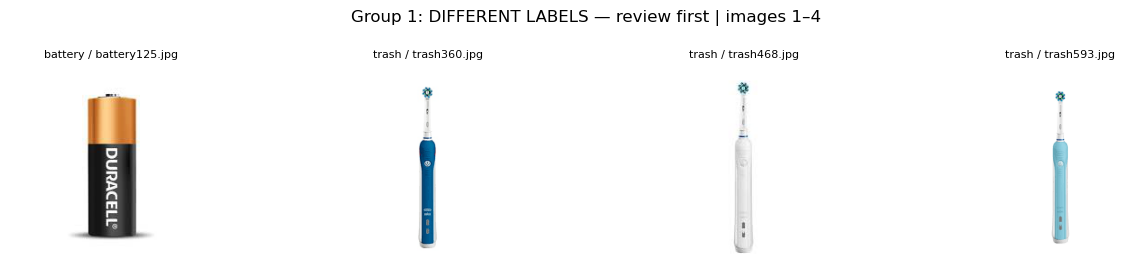

,group_id,filepath,label
4,battery/battery356.jpg,battery/battery356.jpg,battery
5,battery/battery356.jpg,battery/battery487.jpg,battery
6,battery/battery356.jpg,trash/trash380.jpg,trash


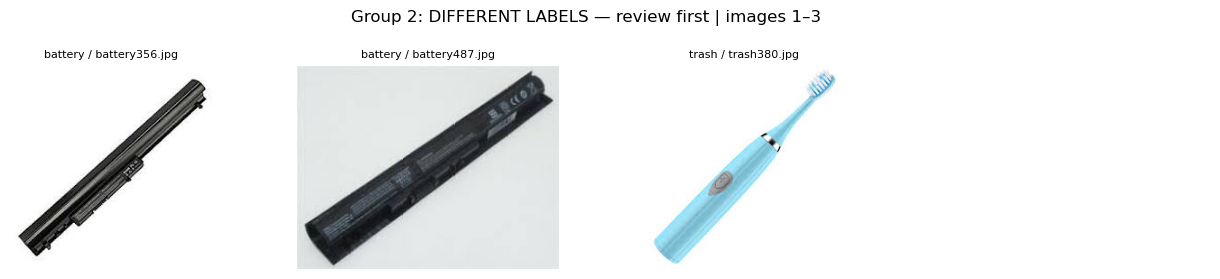

,group_id,filepath,label
7,battery/battery61.jpg,battery/battery61.jpg,battery
8,battery/battery61.jpg,trash/trash357.jpg,trash


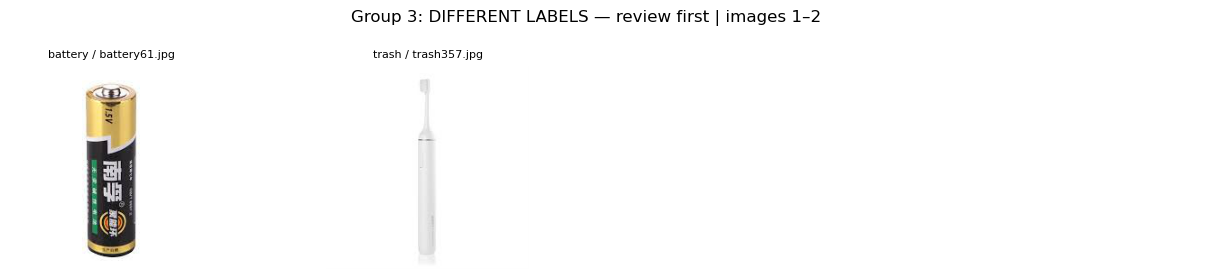

,group_id,filepath,label
9,battery/battery689.jpg,battery/battery689.jpg,battery
10,battery/battery689.jpg,white-glass/white-glass464.jpg,white-glass


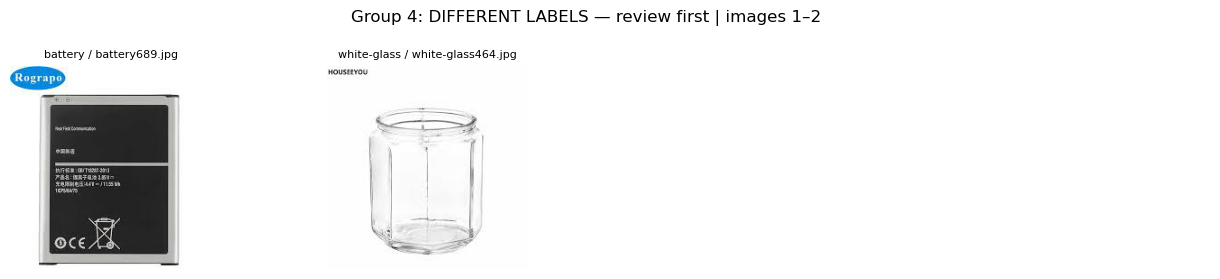

,group_id,filepath,label
11,brown-glass/brown-glass103.jpg,brown-glass/brown-glass103.jpg,brown-glass
12,brown-glass/brown-glass103.jpg,brown-glass/brown-glass189.jpg,brown-glass
13,brown-glass/brown-glass103.jpg,brown-glass/brown-glass94.jpg,brown-glass
14,brown-glass/brown-glass103.jpg,green-glass/green-glass296.jpg,green-glass
15,brown-glass/brown-glass103.jpg,green-glass/green-glass408.jpg,green-glass
16,brown-glass/brown-glass103.jpg,green-glass/green-glass474.jpg,green-glass
17,brown-glass/brown-glass103.jpg,green-glass/green-glass480.jpg,green-glass
18,brown-glass/brown-glass103.jpg,green-glass/green-glass483.jpg,green-glass
19,brown-glass/brown-glass103.jpg,trash/trash370.jpg,trash
20,brown-glass/brown-glass103.jpg,trash/trash409.jpg,trash


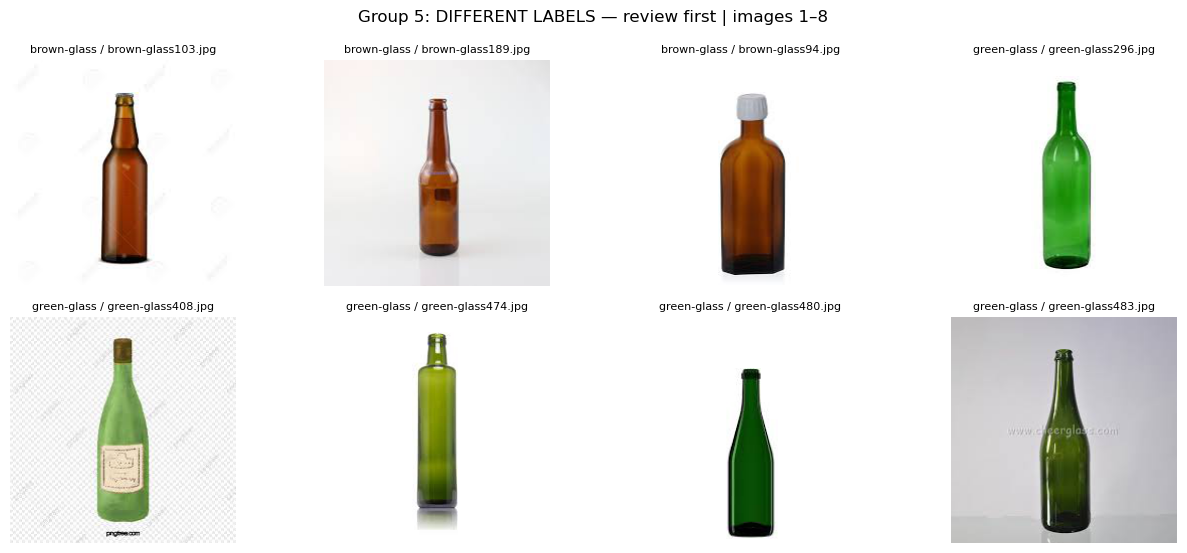

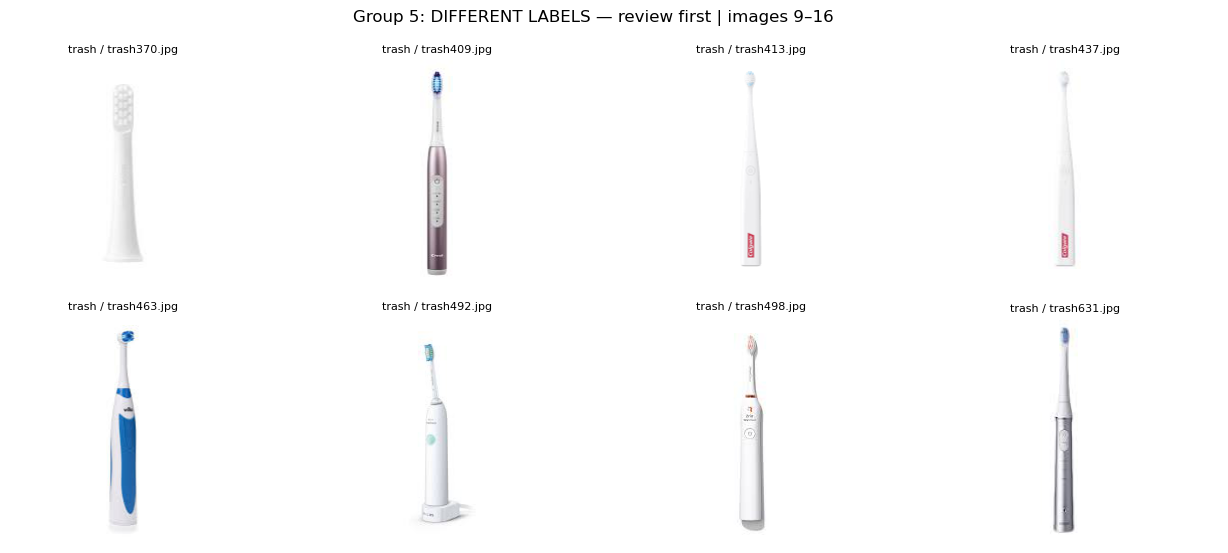

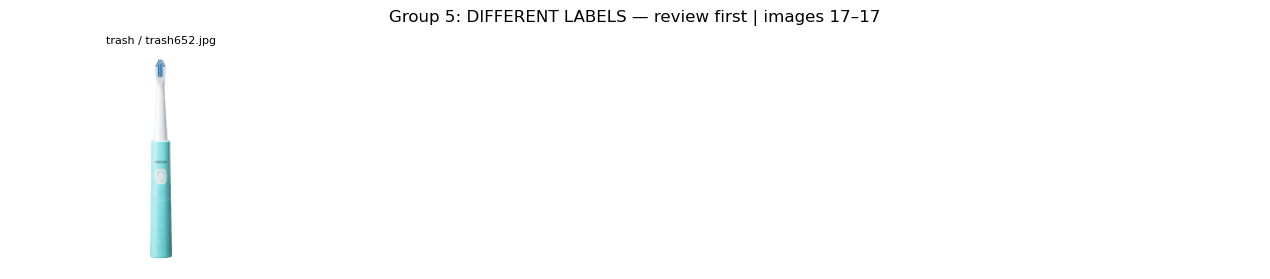

,group_id,filepath,label
28,brown-glass/brown-glass373.jpg,brown-glass/brown-glass373.jpg,brown-glass
29,brown-glass/brown-glass373.jpg,green-glass/green-glass606.jpg,green-glass


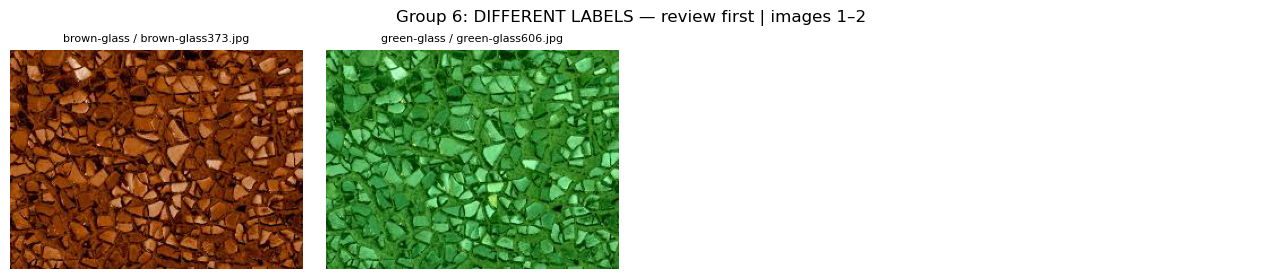

,group_id,filepath,label
30,brown-glass/brown-glass440.jpg,brown-glass/brown-glass440.jpg,brown-glass
31,brown-glass/brown-glass440.jpg,brown-glass/brown-glass597.jpg,brown-glass
32,brown-glass/brown-glass440.jpg,green-glass/green-glass541.jpg,green-glass
33,brown-glass/brown-glass440.jpg,green-glass/green-glass558.jpg,green-glass
34,brown-glass/brown-glass440.jpg,trash/trash465.jpg,trash
35,brown-glass/brown-glass440.jpg,trash/trash502.jpg,trash
36,brown-glass/brown-glass440.jpg,trash/trash526.jpg,trash
37,brown-glass/brown-glass440.jpg,trash/trash533.jpg,trash
38,brown-glass/brown-glass440.jpg,white-glass/white-glass433.jpg,white-glass


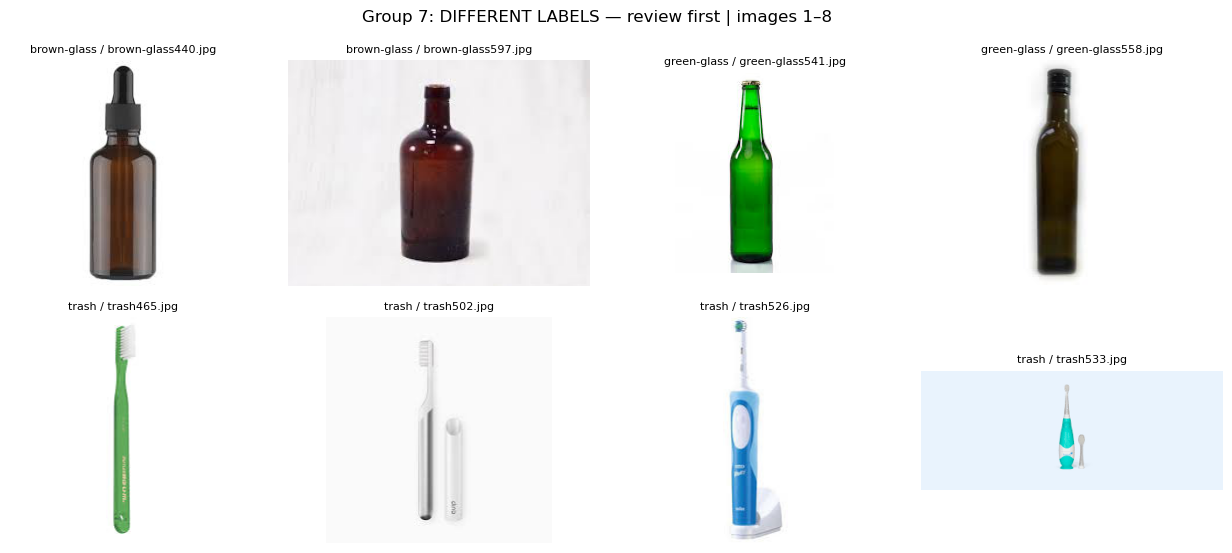

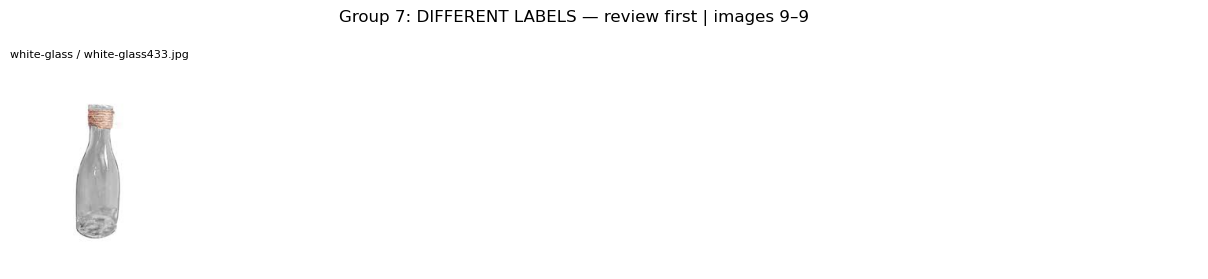

,group_id,filepath,label
39,cardboard/cardboard464.jpg,cardboard/cardboard464.jpg,cardboard
40,cardboard/cardboard464.jpg,trash/trash500.jpg,trash
41,cardboard/cardboard464.jpg,trash/trash564.jpg,trash


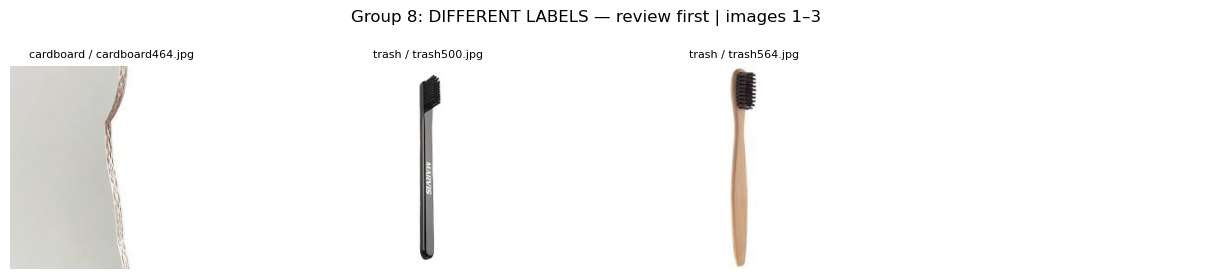

,group_id,filepath,label
42,green-glass/green-glass481.jpg,green-glass/green-glass481.jpg,green-glass
43,green-glass/green-glass481.jpg,plastic/plastic714.jpg,plastic
44,green-glass/green-glass481.jpg,trash/trash521.jpg,trash


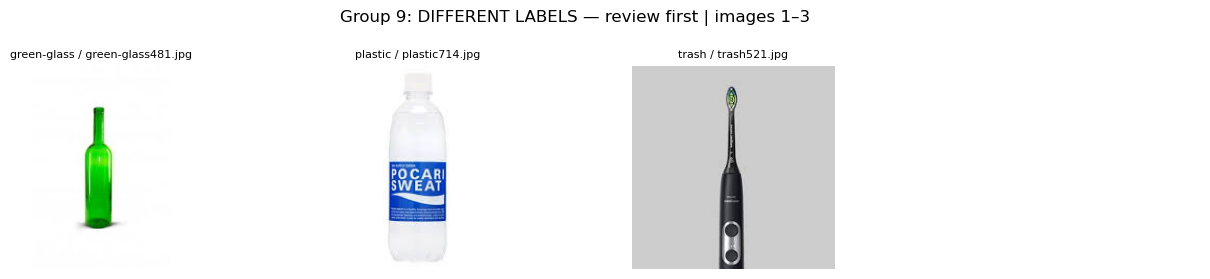

,group_id,filepath,label
45,metal/metal459.jpg,metal/metal459.jpg,metal
46,metal/metal459.jpg,white-glass/white-glass412.jpg,white-glass


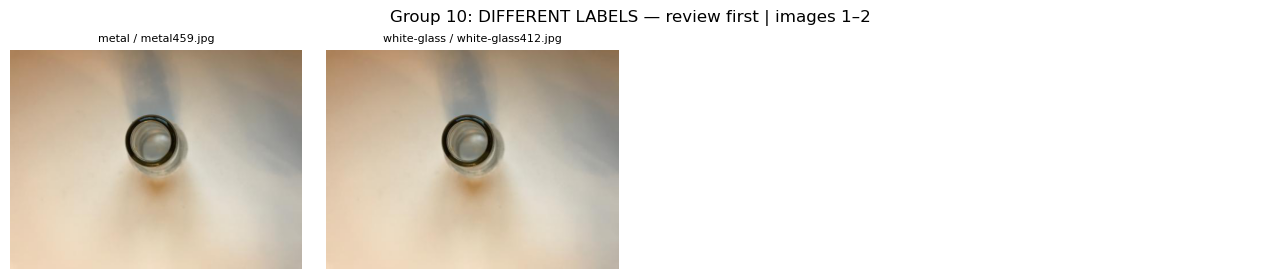

,group_id,filepath,label
47,metal/metal81.jpg,metal/metal81.jpg,metal
48,metal/metal81.jpg,plastic/plastic250.jpg,plastic


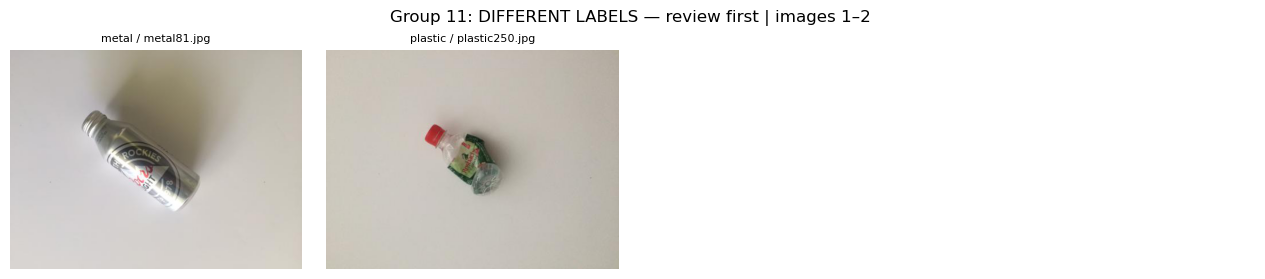

,group_id,filepath,label
49,metal/metal86.jpg,metal/metal86.jpg,metal
50,metal/metal86.jpg,plastic/plastic398.jpg,plastic
51,metal/metal86.jpg,plastic/plastic698.jpg,plastic


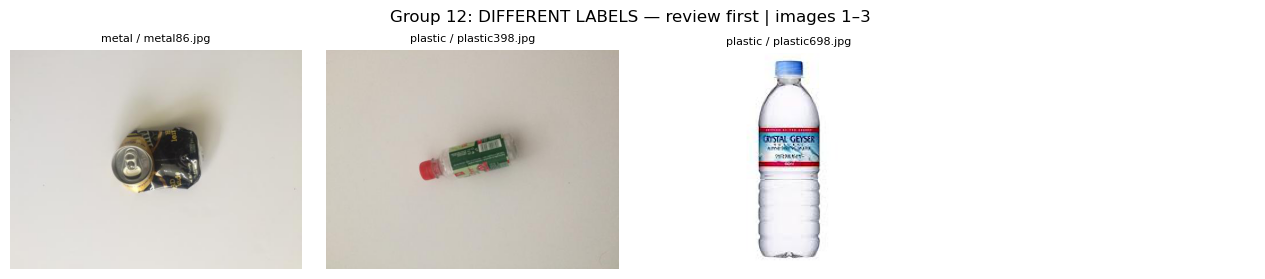

In [9]:
review = pd.read_csv(review_path, dtype={'group_id': str, 'filepath': str, 'label': str})
group_order = review.group_id.drop_duplicates().tolist()
stop = None if REVIEW_LIMIT is None else REVIEW_START + REVIEW_LIMIT
selected_groups = group_order[REVIEW_START:stop]
print(f'Hiển thị {len(selected_groups)} / {len(group_order)} nhóm; bắt đầu ở chỉ số {REVIEW_START}.')
for number, group_id in enumerate(selected_groups, start=REVIEW_START+1):
    group = review.loc[review.group_id.eq(group_id)]
    status = 'DIFFERENT LABELS — review first' if group.label.nunique() > 1 else 'SAME LABEL'
    display(group[['group_id', 'filepath', 'label']])
    for start in range(0, len(group), 8):
        show_gallery(group.iloc[start:start+8], f'Group {number}: {status} | images {start+1}–{min(start+8, len(group))}')


## 7. Tổng kết EDA và giới hạn

Ô dưới tổng hợp trực tiếp từ kết quả chạy. Các nhận xét về nhãn, vật thể và nền cần kiểm tra bằng mắt; notebook không tự xác nhận nhãn đúng/sai.

In [10]:
results = {
    'images': len(inventory), 'readable_images': len(valid),
    'errors': int(inventory.status.ne('ok').sum()), 'warnings': int(inventory.warning.ne('').sum()),
    'classes': int(valid.label.nunique()), 'class_counts': {k: int(v) for k,v in counts.items()},
    'imbalance_ratio': float(imbalance), 'majority_baseline': float(majority_baseline),
    'distinct_dimensions': len(dimensions), 'modes': sorted(valid['mode'].unique()),
    'exact_file_groups': len(file_duplicates), 'exact_pixel_groups': len(pixel_duplicates),
    'redundant_exact_pixel_images': int((pixel_duplicates.n - 1).sum()),
    'cross_label_exact_pixel_groups': len(cross_label_duplicates),
    'phash_threshold': PHASH_THRESHOLD, 'similar_pairs': len(similar_pairs),
    'review_groups': len(duplicate_groups), 'review_images': len(review),
    'cross_label_review_groups': len(cross_label_groups),
    'metadata_class_mismatches': int(distribution.difference_from_download.fillna(0).ne(0).sum()) if EXPECTED else None,
    'seed': SEED,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                 'matplotlib': matplotlib.__version__, 'Pillow': PIL.__version__, 'scipy': scipy.__version__}}
(OUTPUT_DIR / 'summary.json').write_text(json.dumps(results, ensure_ascii=False, indent=2)+'\n', encoding='utf-8')
summary_text = f"""
### Kết quả định lượng
- Kiểm kê **{len(inventory):,}** ảnh, đọc được **{len(valid):,}**, lỗi **{results['errors']}**, cảnh báo **{results['warnings']}**.
- **{results['classes']} lớp**; tỷ lệ lớn nhất/nhỏ nhất có ảnh **{imbalance:.2f} lần**. Baseline luôn đoán lớp đông nhất trên toàn bộ dữ liệu: **{majority_baseline:.2%}**.
- **{len(dimensions)}** kích thước ảnh lưu trữ; chế độ màu: **{', '.join(results['modes'])}**.
- **{len(file_duplicates)} nhóm trùng byte**, **{len(pixel_duplicates)} nhóm trùng pixel**, trong đó **{len(cross_label_duplicates)} nhóm trùng pixel khác nhãn**.
- Nếu mỗi nhóm pixel giống hệt chỉ giữ một ảnh thì có **{results['redundant_exact_pixel_images']} ảnh dư**; notebook chưa xóa ảnh.
- **{len(similar_pairs):,} cặp pHash** trong ngưỡng Hamming ≤ {PHASH_THRESHOLD}, bao gồm ảnh trùng pixel.
- Gom được **{len(duplicate_groups):,} nhóm cần xem lại / {len(review):,} ảnh**, trong đó **{len(cross_label_groups)} nhóm nhiều nhãn**.

### Ý nghĩa đối với bước tiếp theo
- Báo cáo macro-F1, recall từng lớp và confusion matrix; cân nhắc class weights chỉ dựa trên tập train sau khi chia.
- Kiểm tra các nhóm khác nhãn trước; ảnh gần trùng là ứng viên, không phải kết luận nhãn sai.
- Khi chia tập, giữ ảnh cùng nhóm đã xác nhận trong cùng một tập để tránh rò rỉ. Các nhóm pHash có thể có false positive và không bao phủ mọi ảnh cùng vật thể.
- Tách đánh giá trên ảnh thực tế nếu cần kiểm chứng khả năng tổng quát hóa. EDA này không đánh giá mô hình.
- CSV, hình và phiên bản thư viện đã lưu trong `preprocess/eda_outputs/garbage_classification/`.
"""
display(Markdown(summary_text))
(OUTPUT_DIR / 'summary.md').write_text('# Garbage Classification — EDA\n\n'+summary_text, encoding='utf-8')



### Kết quả định lượng
- Kiểm kê **15,515** ảnh, đọc được **15,515**, lỗi **0**, cảnh báo **0**.
- **12 lớp**; tỷ lệ lớn nhất/nhỏ nhất có ảnh **8.77 lần**. Baseline luôn đoán lớp đông nhất trên toàn bộ dữ liệu: **34.32%**.
- **892** kích thước ảnh lưu trữ; chế độ màu: **P, RGB**.
- **18 nhóm trùng byte**, **18 nhóm trùng pixel**, trong đó **3 nhóm trùng pixel khác nhãn**.
- Nếu mỗi nhóm pixel giống hệt chỉ giữ một ảnh thì có **19 ảnh dư**; notebook chưa xóa ảnh.
- **285 cặp pHash** trong ngưỡng Hamming ≤ 4, bao gồm ảnh trùng pixel.
- Gom được **162 nhóm cần xem lại / 368 ảnh**, trong đó **17 nhóm nhiều nhãn**.

### Ý nghĩa đối với bước tiếp theo
- Báo cáo macro-F1, recall từng lớp và confusion matrix; cân nhắc class weights chỉ dựa trên tập train sau khi chia.
- Kiểm tra các nhóm khác nhãn trước; ảnh gần trùng là ứng viên, không phải kết luận nhãn sai.
- Khi chia tập, giữ ảnh cùng nhóm đã xác nhận trong cùng một tập để tránh rò rỉ. Các nhóm pHash có thể có false positive và không bao phủ mọi ảnh cùng vật thể.
- Tách đánh giá trên ảnh thực tế nếu cần kiểm chứng khả năng tổng quát hóa. EDA này không đánh giá mô hình.
- CSV, hình và phiên bản thư viện đã lưu trong `preprocess/eda_outputs/garbage_classification/`.


1263

## 8. Ghi chú kiểm tra thủ công cho báo cáo

Các quan sát dưới đây chỉ dựa trên ảnh mẫu đã xem, không phải kiểm định toàn bộ nhãn:

| Nội dung | Quan sát |
|---|---|
| Nền ảnh và watermark | `biological/biological758.jpg` và `biological/biological429.jpg` có chữ/watermark; một số ảnh sản phẩm có nền trắng. Cần lưu ý nguy cơ mô hình học dấu hiệu nền/nguồn ảnh. |
| Ảnh quần áo | Các mẫu `clothes2690.jpg`, `clothes741.jpg`, `clothes4978.jpg`, `clothes4043.jpg` là quần áo thông thường; không thể suy ra hiệu quả nhận diện quần áo bị vứt bỏ ngoài thực tế. |
| pHash có false positive | Nhóm chứa `battery/battery125.jpg` và `trash/trash360.jpg`, `trash/trash468.jpg`, `trash/trash593.jpg` gồm pin và bàn chải điện, có bố cục dọc trên nền trắng tương tự nhưng là vật thể khác nhau. Không tự động xóa hoặc sửa nhãn theo nhóm này. |
| Các nhóm còn lại | Chưa xác nhận thủ công toàn bộ. Ưu tiên nhóm trùng pixel khác nhãn và 17 nhóm nhiều nhãn trong CSV. |

**Tài liệu tham khảo:** Mostafa Mohamed, [Garbage Classification (12 classes)](https://www.kaggle.com/datasets/mostafaabla/garbage-classification).

Notebook chỉ EDA; không ghi thay đổi vào ảnh gốc.


## 9. Đối chiếu phần mở rộng và nội dung file

Định dạng được Pillow nhận diện từ nội dung ảnh, không suy đoán từ đuôi file.
Ảnh mở được nhưng sai đuôi được ghi riêng để tránh nhầm với lỗi giải mã.


In [ ]:
extension_formats = {'.jpg': 'JPEG', '.jpeg': 'JPEG', '.png': 'PNG',
                     '.bmp': 'BMP', '.tif': 'TIFF', '.tiff': 'TIFF', '.webp': 'WEBP'}
format_audit = inventory.loc[inventory.status.eq('ok'), ['filepath', 'format', 'mode']].copy()
format_audit['extension'] = format_audit.filepath.map(lambda name: Path(name).suffix.lower())
format_audit['expected_format'] = format_audit.extension.map(extension_formats)
format_issues = format_audit.loc[format_audit['format'].ne(format_audit.expected_format)]
format_issues.to_csv(OUTPUT_DIR / 'format_extension_issues.csv', index=False)
display(format_issues)
display(Markdown(f'**{len(format_issues)} ảnh có nội dung khác đuôi file.** '
                 'Khi tiền xử lý, đọc bằng bộ giải mã hỗ trợ định dạng thực, chuyển ảnh sang RGB và '
                 'chọn kích thước đầu vào nhất quán cho mô hình; không coi mọi file .jpg là JPEG/RGB. '
                 'Notebook chỉ ghi nhận, chưa đổi định dạng hoặc tên ảnh.'))
summary_path = OUTPUT_DIR / 'summary.json'
saved_summary = json.loads(summary_path.read_text(encoding='utf-8'))
saved_summary['format_extension_mismatches'] = len(format_issues)
summary_path.write_text(json.dumps(saved_summary, ensure_ascii=False, indent=2)+'\n', encoding='utf-8')


,filepath,format,mode,extension,expected_format
90,battery/battery180.jpg,PNG,P,.jpg,JPEG
128,battery/battery214.jpg,PNG,P,.jpg,JPEG
186,battery/battery267.jpg,PNG,P,.jpg,JPEG
368,battery/battery430.jpg,PNG,P,.jpg,JPEG
400,battery/battery46.jpg,PNG,P,.jpg,JPEG
860,battery/battery874.jpg,PNG,P,.jpg,JPEG
10534,paper/paper399.jpg,PNG,P,.jpg,JPEG
11113,paper/paper92.jpg,PNG,P,.jpg,JPEG
11185,paper/paper985.jpg,PNG,P,.jpg,JPEG
14331,trash/trash359.jpg,PNG,P,.jpg,JPEG


**34 ảnh có nội dung khác đuôi file.** Khi tiền xử lý, đọc bằng bộ giải mã hỗ trợ định dạng thực, chuyển ảnh sang RGB và chọn kích thước đầu vào nhất quán cho mô hình; không coi mọi file .jpg là JPEG/RGB. Notebook chỉ ghi nhận, chưa đổi định dạng hoặc tên ảnh.

1038